# Detecção de fraude em cartão de crédito

Projeto do desafio da DIO: treinar modelos que detectam fraude em transações reais de cartão de crédito, onde **só 0,17% das transações são fraude** e, por isso, a acurácia engana.

**Roteiro**

1. Explorar a base e medir o desbalanceamento
2. Preparar os dados (log do valor, padronização, divisão estratificada)
3. Treinar e comparar: regressão logística (baseline), Random Forest e XGBoost
4. Avaliar pelas métricas da classe de fraude: recall, precisão, F1, curva ROC e curva de precisão e recall
5. Ajustar: Pipeline, limiar de decisão e GridSearchCV
6. Evoluir: undersampling × oversampling, Random Forest no Pipeline com ajuste de limiar, busca maior de hiperparâmetros, variáveis de tempo e outros modelos
7. Explicar: importância das variáveis e SHAP

A base é lida direto do link do desafio, então o notebook roda no Google Colab sem baixar nada.

In [1]:
# XGBoost e SHAP já vêm no Colab; a linha abaixo instala só se faltar.
import importlib.util, subprocess, sys
for pacote in ["xgboost", "shap"]:
    if importlib.util.find_spec(pacote) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pacote])

import warnings
warnings.filterwarnings("ignore")

from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from xgboost import XGBClassifier
import shap

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

## 1. Explorar

`Time` é o número de segundos desde a primeira transação da base (cobre dois dias), `Amount` é o valor e `Class` é a resposta (1 = fraude, 0 = normal). `V1` a `V28` vieram de um PCA aplicado pelo banco para proteger a privacidade, então não têm nome de negócio.

In [2]:
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(DATA_URL)
print("Formato:", df.shape)
df.head()

Formato: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [3]:
print("Valores ausentes:", int(df.isnull().sum().sum()))
print("Linhas duplicadas:", int(df.duplicated().sum()))
print("Fraudes entre as duplicadas:", int(df[df.duplicated()]["Class"].sum()))
df[["Time", "Amount", "Class"]].describe()

Valores ausentes: 0
Linhas duplicadas: 1081
Fraudes entre as duplicadas: 19


,Time,Amount,Class
count,"284,807.0000","284,807.0000","284,807.0000"
mean,"94,813.8596",88.3496,0.0017
std,"47,488.1460",250.1201,0.0415
min,0.0000,0.0000,0.0000
25%,"54,201.5000",5.6000,0.0000
50%,"84,692.0000",22.0000,0.0000
75%,"139,320.5000",77.1650,0.0000
max,"172,792.0000","25,691.1600",1.0000


In [4]:
proporcao = pd.DataFrame({
    "transações": df["Class"].value_counts(),
    "proporção": df["Class"].value_counts(normalize=True),
}).rename(index={0: "normal (0)", 1: "fraude (1)"})
proporcao

,transações,proporção
Class,,
normal (0),284315,0.9983
fraude (1),492,0.0017


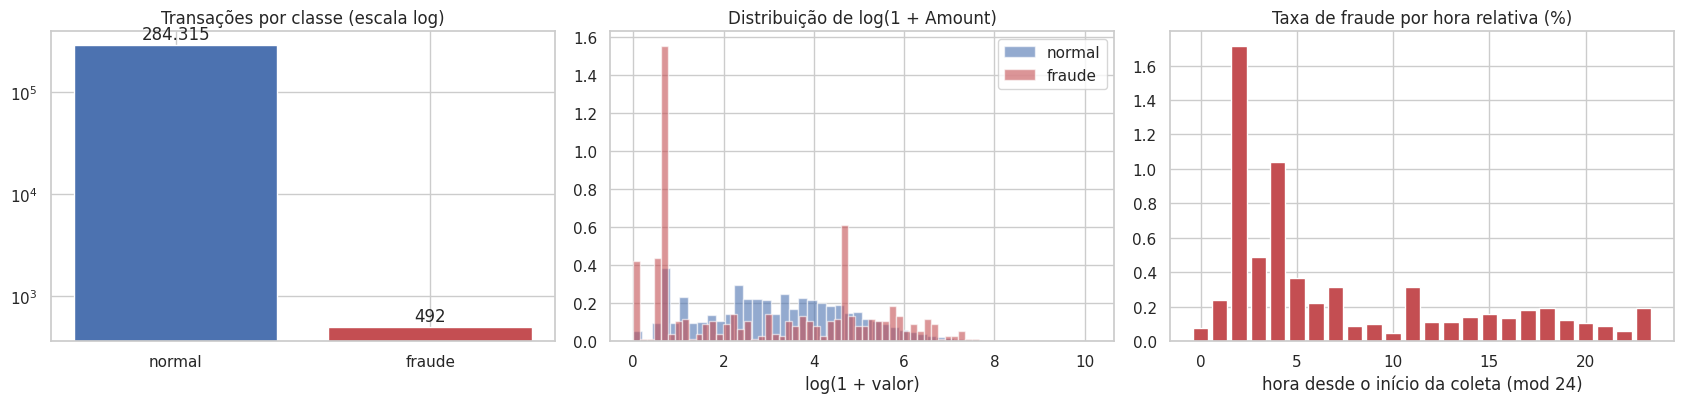

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))

contagem = df["Class"].value_counts().sort_index()
axes[0].bar(["normal", "fraude"], contagem.values, color=["#4C72B0", "#C44E52"])
axes[0].set_yscale("log")
axes[0].set_title("Transações por classe (escala log)")
for i, v in enumerate(contagem.values):
    axes[0].text(i, v * 1.15, f"{v:,}".replace(",", "."), ha="center")

for classe, cor, rotulo in [(0, "#4C72B0", "normal"), (1, "#C44E52", "fraude")]:
    axes[1].hist(np.log1p(df.loc[df["Class"] == classe, "Amount"]), bins=50, density=True,
                 alpha=0.6, color=cor, label=rotulo)
axes[1].set_title("Distribuição de log(1 + Amount)")
axes[1].set_xlabel("log(1 + valor)")
axes[1].legend()

hora = (df["Time"] // 3600) % 24
taxa_hora = df.groupby(hora)["Class"].mean() * 100
axes[2].bar(taxa_hora.index, taxa_hora.values, color="#C44E52")
axes[2].set_title("Taxa de fraude por hora relativa (%)")
axes[2].set_xlabel("hora desde o início da coleta (mod 24)")
plt.tight_layout()
plt.show()

**O que a exploração mostra**

- Não há valores ausentes, mas há linhas duplicadas. Removo as duplicadas para que a mesma transação não caia no treino e no teste ao mesmo tempo, o que inflaria as métricas.
- A fraude é rara (cerca de 0,17%). Um modelo que responde "normal" para tudo já acerta mais de 99,8%.
- A taxa de fraude muda ao longo do dia: nas horas de madrugada (pouco movimento), a proporção de fraude sobe bastante. Isso motiva as variáveis de tempo da seção 6.

## 2. Preparar

- `Amount_log = log1p(Amount)`: o valor é muito assimétrico (muitas compras pequenas e poucas enormes); o log comprime a cauda.
- Variáveis de tempo (usadas só na seção 6.4): hora relativa, segundos desde a transação anterior, número de transações no último minuto e valor comparado com a média das 10 transações anteriores. A base não tem identificador de cartão, então essas variáveis descrevem o movimento geral do sistema, não o de um cliente. Todas usam só o passado de cada transação.
- Divisão treino/teste 80/20 com `stratify=y`, para manter a proporção de fraudes nos dois.
- `StandardScaler` ajustado **só no treino** e aplicado no teste.

In [6]:
df = df.drop_duplicates().reset_index(drop=True)
print("Formato sem duplicadas:", df.shape, "| fraudes:", int(df["Class"].sum()))

df["Amount_log"] = np.log1p(df["Amount"])

# Variáveis de comportamento ao longo do tempo (só olham para o passado)
ordem = df.sort_values("Time", kind="mergesort")
tempo = pd.to_datetime(ordem["Time"], unit="s")
serie_um = pd.Series(1.0, index=tempo)
df.loc[ordem.index, "Hour"] = ((ordem["Time"] // 3600) % 24).values
df.loc[ordem.index, "secs_since_prev"] = ordem["Time"].diff().fillna(0).values
df.loc[ordem.index, "tx_last_60s"] = serie_um.rolling("60s").sum().values
media_10 = ordem["Amount_log"].shift(1).rolling(10, min_periods=1).mean()
df.loc[ordem.index, "amount_vs_last10"] = (ordem["Amount_log"] - media_10).fillna(0).values

V_COLS = [f"V{i}" for i in range(1, 29)]
FEATURES = V_COLS + ["Amount_log"]
TIME_FEATURES = ["Hour", "secs_since_prev", "tx_last_60s", "amount_vs_last10"]

train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["Class"], random_state=SEED)
X_train, X_test = train_df[FEATURES], test_df[FEATURES]
y_train, y_test = train_df["Class"].values, test_df["Class"].values

scaler = StandardScaler().fit(X_train)          # ajusta só no treino
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

pd.DataFrame({
    "linhas": [len(y_train), len(y_test)],
    "fraudes": [y_train.sum(), y_test.sum()],
    "proporção de fraude": [y_train.mean(), y_test.mean()],
}, index=["treino", "teste"])

Formato sem duplicadas: (283726, 31) | fraudes: 473


,linhas,fraudes,proporção de fraude
treino,226980,378,0.0017
teste,56746,95,0.0017


## 3. Treinar

Antes dos modelos de verdade, um classificador "burro" que sempre responde **normal** mostra a armadilha da acurácia.

Uma função de avaliação calcula as métricas da **classe de fraude**:

- **recall**: das fraudes reais, quantas o modelo encontrou;
- **precisão**: das transações marcadas como fraude, quantas eram fraude;
- **F1**: média harmônica das duas;
- **PR-AUC (average precision)**: área sob a curva de precisão e recall, que resume o modelo em todos os limiares e não se deixa inflar pela classe majoritária como a ROC-AUC.

Os modelos de árvore recebem os dados sem padronizar (árvores não dependem de escala e, assim, o SHAP mostra os valores originais). A regressão logística recebe os dados padronizados.

In [7]:
def avaliar(nome, y_true, proba, limiar=0.5):
    pred = (proba >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "modelo": nome,
        "limiar": limiar,
        "acurácia": accuracy_score(y_true, pred),
        "precisão": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "fraudes pegas": f"{tp}/{tp + fn}",
        "falsos positivos": int(fp),
    }

dummy = DummyClassifier(strategy="most_frequent").fit(X_train_s, y_train)
pd.DataFrame([avaliar("Sempre 'normal'", y_test, dummy.predict_proba(X_test_s)[:, 1])])

,modelo,limiar,acurácia,precisão,recall,F1,ROC-AUC,PR-AUC,fraudes pegas,falsos positivos
0,Sempre 'normal',0.5000,0.9983,0.0000,0.0000,0.0000,0.5000,0.0017,0/95,0


Acurácia de 99,8% e **zero fraudes encontradas**. É por isso que a partir daqui o foco é recall, precisão e F1 da classe 1.

In [8]:
neg, pos = np.bincount(y_train)
peso_xgb = neg / pos
print(f"Normais por fraude no treino: {peso_xgb:.0f}")

modelos = {
    "Regressão logística": (LogisticRegression(max_iter=1000, random_state=SEED), "escalado"),
    "Regressão logística (balanced)": (LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED), "escalado"),
    "Random Forest (balanced)": (RandomForestClassifier(n_estimators=200, class_weight="balanced", min_samples_leaf=2,
                                                        n_jobs=-1, random_state=SEED), "bruto"),
    "XGBoost": (XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                              eval_metric="aucpr", tree_method="hist", n_jobs=-1, random_state=SEED), "bruto"),
    "XGBoost (scale_pos_weight)": (XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8,
                                                 colsample_bytree=0.8, scale_pos_weight=peso_xgb, eval_metric="aucpr",
                                                 tree_method="hist", n_jobs=-1, random_state=SEED), "bruto"),
}

probas, tempos = {}, {}
for nome, (modelo, entrada) in modelos.items():
    Xtr, Xte = (X_train_s, X_test_s) if entrada == "escalado" else (X_train, X_test)
    inicio = perf_counter()
    modelo.fit(Xtr, y_train)
    tempos[nome] = perf_counter() - inicio
    probas[nome] = modelo.predict_proba(Xte)[:, 1]
    print(f"{nome:<32} treinado em {tempos[nome]:6.1f}s")

resultados = pd.DataFrame([avaliar(n, y_test, p) for n, p in probas.items()])
resultados

Normais por fraude no treino: 599
Regressão logística              treinado em    1.7s
Regressão logística (balanced)   treinado em    3.2s
Random Forest (balanced)         treinado em  334.9s
XGBoost                          treinado em   17.8s
XGBoost (scale_pos_weight)       treinado em   21.5s


,modelo,limiar,acurácia,precisão,recall,F1,ROC-AUC,PR-AUC,fraudes pegas,falsos positivos
0,Regressão logística,0.5000,0.9991,0.8485,0.5895,0.6957,0.9541,0.6999,56/95,10
1,Regressão logística (balanced),0.5000,0.9747,0.0551,0.8737,0.1037,0.9615,0.6774,83/95,1422
2,Random Forest (balanced),0.5000,0.9995,0.9857,0.7263,0.8364,0.9384,0.8150,69/95,1
3,XGBoost,0.5000,0.9996,0.9730,0.7579,0.8521,0.9732,0.8352,72/95,2
4,XGBoost (scale_pos_weight),0.5000,0.9995,0.9036,0.7895,0.8427,0.9733,0.8195,75/95,8


## 4. Avaliar

Relatório de classificação, matrizes de confusão, curva ROC e curva de precisão e recall.

In [9]:
for nome, proba in probas.items():
    print(f"=== {nome} (limiar 0,5) ===")
    print(classification_report(y_test, (proba >= 0.5).astype(int), target_names=["normal", "fraude"], digits=4))

=== Regressão logística (limiar 0,5) ===
              precision    recall  f1-score   support

      normal     0.9993    0.9998    0.9996     56651
      fraude     0.8485    0.5895    0.6957        95

    accuracy                         0.9991     56746
   macro avg     0.9239    0.7946    0.8476     56746
weighted avg     0.9991    0.9991    0.9991     56746

=== Regressão logística (balanced) (limiar 0,5) ===
              precision    recall  f1-score   support

      normal     0.9998    0.9749    0.9872     56651
      fraude     0.0551    0.8737    0.1037        95

    accuracy                         0.9747     56746
   macro avg     0.5275    0.9243    0.5455     56746
weighted avg     0.9982    0.9747    0.9857     56746

=== Random Forest (balanced) (limiar 0,5) ===
              precision    recall  f1-score   support

      normal     0.9995    1.0000    0.9998     56651
      fraude     0.9857    0.7263    0.8364        95

    accuracy                         0.9995

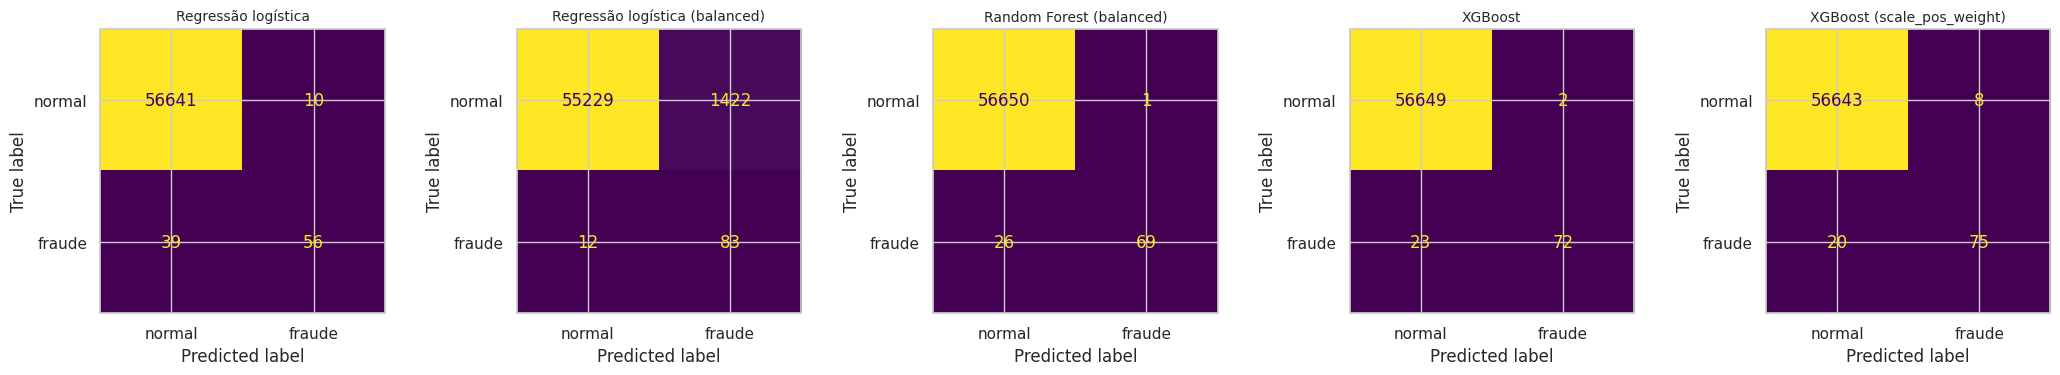

In [10]:
fig, axes = plt.subplots(1, len(probas), figsize=(4.2 * len(probas), 3.8))
for ax, (nome, proba) in zip(axes, probas.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (proba >= 0.5).astype(int)),
                           display_labels=["normal", "fraude"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(nome, fontsize=10)
plt.tight_layout()
plt.show()

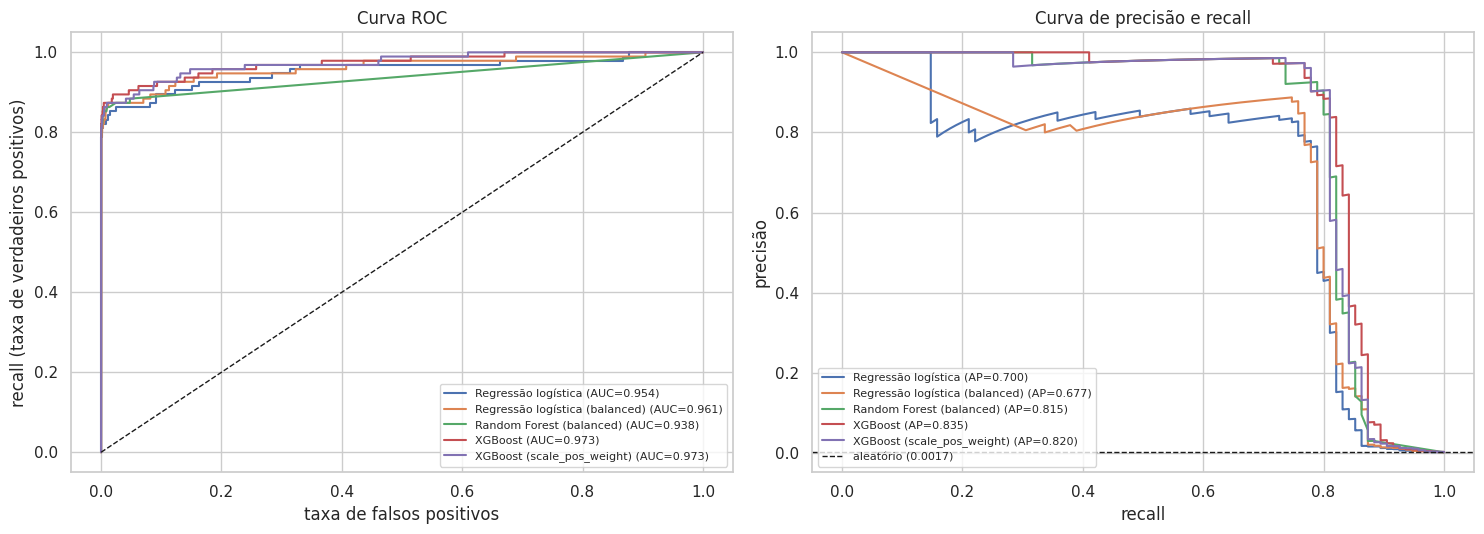

In [11]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(15, 5.5))
for nome, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax_roc.plot(fpr, tpr, label=f"{nome} (AUC={roc_auc_score(y_test, proba):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ax_pr.plot(rec, prec, label=f"{nome} (AP={average_precision_score(y_test, proba):.3f})")
ax_roc.plot([0, 1], [0, 1], "k--", lw=1)
ax_roc.set(title="Curva ROC", xlabel="taxa de falsos positivos", ylabel="recall (taxa de verdadeiros positivos)")
ax_pr.axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"aleatório ({y_test.mean():.4f})")
ax_pr.set(title="Curva de precisão e recall", xlabel="recall", ylabel="precisão")
ax_roc.legend(fontsize=8, loc="lower right"); ax_pr.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

**Como ler**

- Na **curva ROC** todos os modelos parecem excelentes (AUC entre 0,93 e 0,98). Isso acontece porque o eixo x é a taxa de falsos positivos sobre ~57 mil transações normais: centenas de alarmes falsos ainda dão uma taxa minúscula.
- A **curva de precisão e recall** é a que separa os modelos: a linha tracejada (sorteio) fica em 0,17%, e quanto mais a curva se mantém alta à direita, mais fraudes o modelo pega sem encher a fila de alarmes falsos.
- Dar peso à fraude (`class_weight="balanced"` na regressão logística) sobe o recall, mas derruba a precisão: o modelo passa a marcar milhares de transações normais.

## 5. Ajustar

### 5.1 Pipeline + limiar de decisão

O `Pipeline` junta padronização e modelo, então o `StandardScaler` é reajustado dentro de cada dobra da validação cruzada e nunca vê dados de teste. Depois, comparo o limiar padrão de 0,5 com o limiar de 0,3 usado pela Expert.

In [12]:
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000, random_state=SEED)),
])
pipe_lr.fit(X_train, y_train)
proba_pipe_lr = pipe_lr.predict_proba(X_test)[:, 1]
pd.DataFrame([avaliar("LR Pipeline", y_test, proba_pipe_lr, 0.5),
              avaliar("LR Pipeline", y_test, proba_pipe_lr, 0.3)])

,modelo,limiar,acurácia,precisão,recall,F1,ROC-AUC,PR-AUC,fraudes pegas,falsos positivos
0,LR Pipeline,0.5000,0.9991,0.8485,0.5895,0.6957,0.9541,0.6999,56/95,10
1,LR Pipeline,0.3000,0.9992,0.8243,0.6421,0.7219,0.9541,0.6999,61/95,13


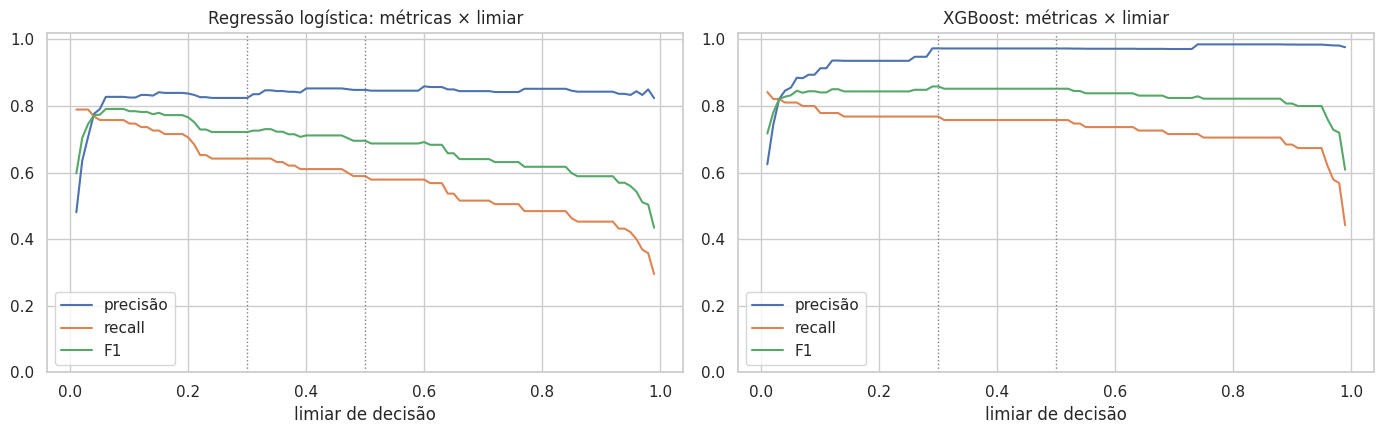

In [13]:
def curva_limiar(y_true, proba, titulo, ax, marcar=(0.3, 0.5)):
    limiares = np.linspace(0.01, 0.99, 99)
    linhas = [avaliar("", y_true, proba, t) for t in limiares]
    ax.plot(limiares, [l["precisão"] for l in linhas], label="precisão")
    ax.plot(limiares, [l["recall"] for l in linhas], label="recall")
    ax.plot(limiares, [l["F1"] for l in linhas], label="F1")
    for t in marcar:
        ax.axvline(t, color="gray", ls=":", lw=1)
    ax.set(title=titulo, xlabel="limiar de decisão", ylim=(0, 1.02))
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
curva_limiar(y_test, proba_pipe_lr, "Regressão logística: métricas × limiar", axes[0])
curva_limiar(y_test, probas["XGBoost"], "XGBoost: métricas × limiar", axes[1])
plt.tight_layout()
plt.show()

Baixar o limiar troca precisão por recall: mais fraudes entram na rede, junto com mais alarmes falsos. O quanto vale a pena depende do custo de cada erro (uma fraude perdida custa o valor da compra; um alarme falso custa uma ligação ou um cliente irritado).

### 5.2 GridSearchCV escolhendo pelo recall

A busca usa validação cruzada estratificada de 5 dobras dentro do treino. Peço recall como critério de escolha (`refit="recall"`), como no desafio, mas registro também precisão, F1 e PR-AUC de cada combinação para ver o preço dessa escolha. A grade é maior que a da aula: 5 valores de `C` × 4 opções de peso para a fraude.

In [14]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grade_lr = {
    "modelo__C": [0.001, 0.01, 0.1, 1, 10],
    "modelo__class_weight": [None, {0: 1, 1: 10}, {0: 1, 1: 50}, "balanced"],
}
grid_lr = GridSearchCV(pipe_lr, grade_lr, cv=cv5, n_jobs=-1, refit="recall",
                       scoring={"recall": "recall", "precisão": "precision", "F1": "f1", "PR-AUC": "average_precision"})
inicio = perf_counter()
grid_lr.fit(X_train, y_train)
print(f"GridSearchCV em {perf_counter() - inicio:.0f}s | melhor por recall: {grid_lr.best_params_}")

cv_res = pd.DataFrame(grid_lr.cv_results_)
tabela_grid = pd.DataFrame({
    "C": cv_res["param_modelo__C"],
    "class_weight": cv_res["param_modelo__class_weight"].astype(str),
    "recall": cv_res["mean_test_recall"],
    "precisão": cv_res["mean_test_precisão"],
    "F1": cv_res["mean_test_F1"],
    "PR-AUC": cv_res["mean_test_PR-AUC"],
}).sort_values("recall", ascending=False)
tabela_grid.head(10)

GridSearchCV em 63s | melhor por recall: {'modelo__C': 0.01, 'modelo__class_weight': 'balanced'}


,C,class_weight,recall,precisão,F1,PR-AUC
15,1.0000,balanced,0.9073,0.0576,0.1082,0.7562
19,10.0000,balanced,0.9073,0.0576,0.1082,0.7564
11,0.1000,balanced,0.9073,0.0579,0.1087,0.7559
7,0.0100,balanced,0.9073,0.0594,0.1114,0.7550
3,0.0010,balanced,0.9021,0.0658,0.1226,0.7372
14,1.0000,"{0: 1, 1: 50}",0.8624,0.4944,0.6279,0.7564
10,0.1000,"{0: 1, 1: 50}",0.8624,0.4973,0.6303,0.7563
18,10.0000,"{0: 1, 1: 50}",0.8624,0.4944,0.6279,0.7566
6,0.0100,"{0: 1, 1: 50}",0.8624,0.5100,0.6405,0.7552
2,0.0010,"{0: 1, 1: 50}",0.8466,0.5908,0.6954,0.7484


In [15]:
melhor_f1 = tabela_grid.sort_values("F1", ascending=False).iloc[0]
print("Melhor combinação por F1 na validação cruzada:")
print(melhor_f1.to_string())

proba_grid_lr = grid_lr.best_estimator_.predict_proba(X_test)[:, 1]
pd.DataFrame([avaliar("LR GridSearch (recall)", y_test, proba_grid_lr, 0.5)])

Melhor combinação por F1 na validação cruzada:
C                      0.0100
class_weight    {0: 1, 1: 10}
recall                 0.8201
precisão               0.7640
F1                     0.7901
PR-AUC                 0.7568


,modelo,limiar,acurácia,precisão,recall,F1,ROC-AUC,PR-AUC,fraudes pegas,falsos positivos
0,LR GridSearch (recall),0.5000,0.9754,0.0567,0.8737,0.1064,0.9615,0.6677,83/95,1382


Escolher **só** pelo recall leva a grade para o peso mais alto da fraude e para regularização forte: o recall sobe, mas a precisão cai para poucos por cento, ou seja, a maioria dos alertas é alarme falso. Por isso, na escolha final (seção 6.2) uso o recall como prioridade, mas com uma métrica que também cobra precisão.

## 6. Ideias para evoluir

### 6.1 Undersampling × oversampling

A amostragem é feita **só no treino**; o teste continua com a proporção real de fraude.

- **Undersampling**: mantém todas as fraudes e sorteia o mesmo número de normais (~750 linhas no total).
- **Oversampling**: mantém todas as normais e repete fraudes sorteadas com reposição até empatar (~450 mil linhas).

In [16]:
rng = np.random.default_rng(SEED)
idx_fraude = np.where(y_train == 1)[0]
idx_normal = np.where(y_train == 0)[0]
idx_under = np.concatenate([idx_fraude, rng.choice(idx_normal, size=len(idx_fraude), replace=False)])
idx_over = np.concatenate([idx_normal, rng.choice(idx_fraude, size=len(idx_normal), replace=True)])

def novo_lr():
    return Pipeline([("scaler", StandardScaler()), ("modelo", LogisticRegression(max_iter=1000, random_state=SEED))])

def novo_xgb(**extra):
    params = dict(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                  eval_metric="aucpr", tree_method="hist", n_jobs=-1, random_state=SEED)
    params.update(extra)
    return XGBClassifier(**params)

amostragem = []
for estrategia, idx in [("sem amostragem", np.arange(len(y_train))), ("undersampling", idx_under), ("oversampling", idx_over)]:
    for nome_modelo, fabrica in [("LR", novo_lr), ("XGBoost", novo_xgb)]:
        m = fabrica().fit(X_train.iloc[idx], y_train[idx])
        linha = avaliar(f"{nome_modelo} | {estrategia}", y_test, m.predict_proba(X_test)[:, 1])
        linha["linhas de treino"] = len(idx)
        amostragem.append(linha)
tabela_amostragem = pd.DataFrame(amostragem)
tabela_amostragem

,modelo,limiar,acurácia,precisão,recall,F1,ROC-AUC,PR-AUC,fraudes pegas,falsos positivos,linhas de treino
0,LR | sem amostragem,0.5000,0.9991,0.8485,0.5895,0.6957,0.9541,0.6999,56/95,10,226980
1,XGBoost | sem amostragem,0.5000,0.9996,0.9730,0.7579,0.8521,0.9732,0.8352,72/95,2,226980
2,LR | undersampling,0.5000,0.9713,0.0489,0.8737,0.0926,0.9600,0.4217,83/95,1614,756
3,XGBoost | undersampling,0.5000,0.9733,0.0524,0.8737,0.0988,0.9727,0.6914,83/95,1502,756
4,LR | oversampling,0.5000,0.9749,0.0554,0.8737,0.1043,0.9612,0.6743,83/95,1414,453204
5,XGBoost | oversampling,0.5000,0.9995,0.8916,0.7789,0.8315,0.9711,0.8201,74/95,9,453204


### 6.2 Random Forest no Pipeline com ajuste de limiar (e o mesmo para LR e XGBoost)

Escolher o limiar olhando o conjunto de teste é vazamento: o número final ficaria otimista. Aqui o limiar é escolhido com **previsões fora da dobra** (`cross_val_predict`, 3 dobras) dentro do treino, e só depois aplicado ao teste.

O critério é o **F2**, que dá ao recall o dobro do peso da precisão. Ele segue a prioridade do desafio (pegar fraude), mas não deixa a precisão ir a zero como o recall puro.

In [17]:
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

def escolher_limiar(y_true, proba, beta=2):
    prec, rec, limiares = precision_recall_curve(y_true, proba)
    fbeta = (1 + beta**2) * prec * rec / np.maximum(beta**2 * prec + rec, 1e-12)
    i = int(np.nanargmax(fbeta[:-1]))
    return float(limiares[i])

candidatos = {
    "LR Pipeline": novo_lr(),
    "RF Pipeline (balanced)": Pipeline([("scaler", StandardScaler()),
                                         ("modelo", RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                                                           min_samples_leaf=2, n_jobs=-1, random_state=SEED))]),
    "XGBoost": novo_xgb(),
}

limiares_oof, finais, probas_finais = {}, [], {}
for nome, modelo in candidatos.items():
    inicio = perf_counter()
    oof = cross_val_predict(modelo, X_train, y_train, cv=cv3, method="predict_proba", n_jobs=1)[:, 1]
    limiares_oof[nome] = escolher_limiar(y_train, oof)
    modelo.fit(X_train, y_train)
    probas_finais[nome] = modelo.predict_proba(X_test)[:, 1]
    for t in [0.5, 0.3, limiares_oof[nome]]:
        finais.append(avaliar(nome, y_test, probas_finais[nome], round(t, 3)))
    print(f"{nome:<24} limiar F2 (fora da dobra) = {limiares_oof[nome]:.3f}  [{perf_counter() - inicio:.0f}s]")

tabela_limiar = pd.DataFrame(finais)
tabela_limiar

LR Pipeline              limiar F2 (fora da dobra) = 0.045  [4s]
RF Pipeline (balanced)   limiar F2 (fora da dobra) = 0.190  [890s]
XGBoost                  limiar F2 (fora da dobra) = 0.050  [61s]


,modelo,limiar,acurácia,precisão,recall,F1,ROC-AUC,PR-AUC,fraudes pegas,falsos positivos
0,LR Pipeline,0.5000,0.9991,0.8485,0.5895,0.6957,0.9541,0.6999,56/95,10
1,LR Pipeline,0.3000,0.9992,0.8243,0.6421,0.7219,0.9541,0.6999,61/95,13
2,LR Pipeline,0.0450,0.9993,0.7935,0.7684,0.7807,0.9541,0.6999,73/95,19
3,RF Pipeline (balanced),0.5000,0.9995,0.9857,0.7263,0.8364,0.9384,0.8150,69/95,1
4,RF Pipeline (balanced),0.3000,0.9995,0.9211,0.7368,0.8187,0.9384,0.8150,70/95,6
5,RF Pipeline (balanced),0.1900,0.9995,0.9259,0.7895,0.8523,0.9384,0.8150,75/95,6
6,XGBoost,0.5000,0.9996,0.9730,0.7579,0.8521,0.9732,0.8352,72/95,2
7,XGBoost,0.3000,0.9996,0.9733,0.7684,0.8588,0.9732,0.8352,73/95,2
8,XGBoost,0.0500,0.9995,0.8556,0.8105,0.8324,0.9732,0.8352,77/95,13


### 6.3 Busca de hiperparâmetros maior para o XGBoost

Uma grade pequena (profundidade × taxa de aprendizado × peso da fraude) com validação cruzada de 3 dobras, escolhendo pela **PR-AUC**, que mede a qualidade do ranking em todos os limiares. O limiar é decidido depois, pelo F2.

In [18]:
grade_xgb = {
    "max_depth": [3, 5, 7],
    "learning_rate": [0.05, 0.1],
    "scale_pos_weight": [1, 5, 25],
}
grid_xgb = GridSearchCV(novo_xgb(n_estimators=300, n_jobs=1), grade_xgb, cv=cv3, n_jobs=-1, refit="PR-AUC",
                        scoring={"recall": "recall", "precisão": "precision", "F1": "f1", "PR-AUC": "average_precision"})
inicio = perf_counter()
grid_xgb.fit(X_train, y_train)
print(f"GridSearchCV XGBoost em {perf_counter() - inicio:.0f}s | melhor por PR-AUC: {grid_xgb.best_params_}")

r = pd.DataFrame(grid_xgb.cv_results_)
pd.DataFrame({
    "max_depth": r["param_max_depth"], "learning_rate": r["param_learning_rate"],
    "scale_pos_weight": r["param_scale_pos_weight"],
    "recall": r["mean_test_recall"], "precisão": r["mean_test_precisão"],
    "F1": r["mean_test_F1"], "PR-AUC": r["mean_test_PR-AUC"],
}).sort_values("PR-AUC", ascending=False).head(8)

GridSearchCV XGBoost em 501s | melhor por PR-AUC: {'learning_rate': 0.05, 'max_depth': 5, 'scale_pos_weight': 25}


,max_depth,learning_rate,scale_pos_weight,recall,precisão,F1,PR-AUC
5,5,0.0500,25,0.8175,0.9136,0.8618,0.8533
3,5,0.0500,1,0.7857,0.9447,0.8566,0.8530
6,7,0.0500,1,0.7831,0.9476,0.8562,0.8517
4,5,0.0500,5,0.8069,0.9325,0.8635,0.8502
14,5,0.1000,25,0.8175,0.9168,0.8628,0.8496
8,7,0.0500,25,0.8228,0.9172,0.8661,0.8489
0,3,0.0500,1,0.7804,0.9274,0.8456,0.8485
7,7,0.0500,5,0.8069,0.9292,0.8622,0.8483


### 6.4 Variáveis de comportamento ao longo do tempo

O mesmo XGBoost, agora com hora relativa, segundos desde a transação anterior, transações no último minuto e valor comparado com as 10 transações anteriores.

In [19]:
FEATURES_T = FEATURES + TIME_FEATURES
xgb_tempo = novo_xgb(**grid_xgb.best_params_)
oof_t = cross_val_predict(xgb_tempo, train_df[FEATURES_T], y_train, cv=cv3, method="predict_proba", n_jobs=1)[:, 1]
limiar_t = escolher_limiar(y_train, oof_t)
xgb_tempo.fit(train_df[FEATURES_T], y_train)
proba_tempo = xgb_tempo.predict_proba(test_df[FEATURES_T])[:, 1]

xgb_sem = novo_xgb(**grid_xgb.best_params_)
oof_s = cross_val_predict(xgb_sem, X_train, y_train, cv=cv3, method="predict_proba", n_jobs=1)[:, 1]
limiar_s = escolher_limiar(y_train, oof_s)
xgb_sem.fit(X_train, y_train)
proba_sem = xgb_sem.predict_proba(X_test)[:, 1]

pd.DataFrame([
    avaliar("XGBoost ajustado, sem tempo", y_test, proba_sem, round(limiar_s, 3)),
    avaliar("XGBoost ajustado, com tempo", y_test, proba_tempo, round(limiar_t, 3)),
])

,modelo,limiar,acurácia,precisão,recall,F1,ROC-AUC,PR-AUC,fraudes pegas,falsos positivos
0,"XGBoost ajustado, sem tempo",0.2560,0.9995,0.9367,0.7789,0.8506,0.9784,0.8293,74/95,5
1,"XGBoost ajustado, com tempo",0.1190,0.9994,0.8409,0.7789,0.8087,0.9758,0.8177,74/95,14


### 6.5 Outros modelos de classificação

`HistGradientBoostingClassifier` (boosting do próprio scikit-learn) e `ExtraTreesClassifier`, com o mesmo procedimento de limiar fora da dobra.

In [20]:
outros = {
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=SEED),
    "Extra Trees (balanced)": ExtraTreesClassifier(n_estimators=200, class_weight="balanced", min_samples_leaf=2,
                                                   n_jobs=-1, random_state=SEED),
}
for nome, modelo in outros.items():
    inicio = perf_counter()
    oof = cross_val_predict(modelo, X_train, y_train, cv=cv3, method="predict_proba", n_jobs=1)[:, 1]
    limiares_oof[nome] = escolher_limiar(y_train, oof)
    modelo.fit(X_train, y_train)
    probas_finais[nome] = modelo.predict_proba(X_test)[:, 1]
    print(f"{nome:<24} limiar F2 = {limiares_oof[nome]:.3f}  [{perf_counter() - inicio:.0f}s]")

limiares_oof["XGBoost ajustado"] = limiar_s
probas_finais["XGBoost ajustado"] = proba_sem
limiares_oof["XGBoost ajustado + tempo"] = limiar_t
probas_finais["XGBoost ajustado + tempo"] = proba_tempo

HistGradientBoosting     limiar F2 = 0.725  [7s]
Extra Trees (balanced)   limiar F2 = 0.394  [107s]


### Comparação final

Todos os modelos no conjunto de teste, cada um no limiar escolhido pelo F2 fora da dobra, ordenados por recall.

In [21]:
comparacao = pd.DataFrame([avaliar(n, y_test, p, round(limiares_oof[n], 3)) for n, p in probas_finais.items()])
comparacao = comparacao.sort_values(["recall", "precisão"], ascending=False).reset_index(drop=True)
comparacao

,modelo,limiar,acurácia,precisão,recall,F1,ROC-AUC,PR-AUC,fraudes pegas,falsos positivos
0,XGBoost,0.0500,0.9995,0.8556,0.8105,0.8324,0.9732,0.8352,77/95,13
1,RF Pipeline (balanced),0.1900,0.9995,0.9259,0.7895,0.8523,0.9384,0.8150,75/95,6
2,XGBoost ajustado,0.2560,0.9995,0.9367,0.7789,0.8506,0.9784,0.8293,74/95,5
3,XGBoost ajustado + tempo,0.1190,0.9994,0.8409,0.7789,0.8087,0.9758,0.8177,74/95,14
4,Extra Trees (balanced),0.3940,0.9995,0.9012,0.7684,0.8295,0.9523,0.8106,73/95,8
5,LR Pipeline,0.0450,0.9993,0.7935,0.7684,0.7807,0.9541,0.6999,73/95,19
6,HistGradientBoosting,0.7250,0.9988,0.6239,0.7158,0.6667,0.7828,0.6215,68/95,41


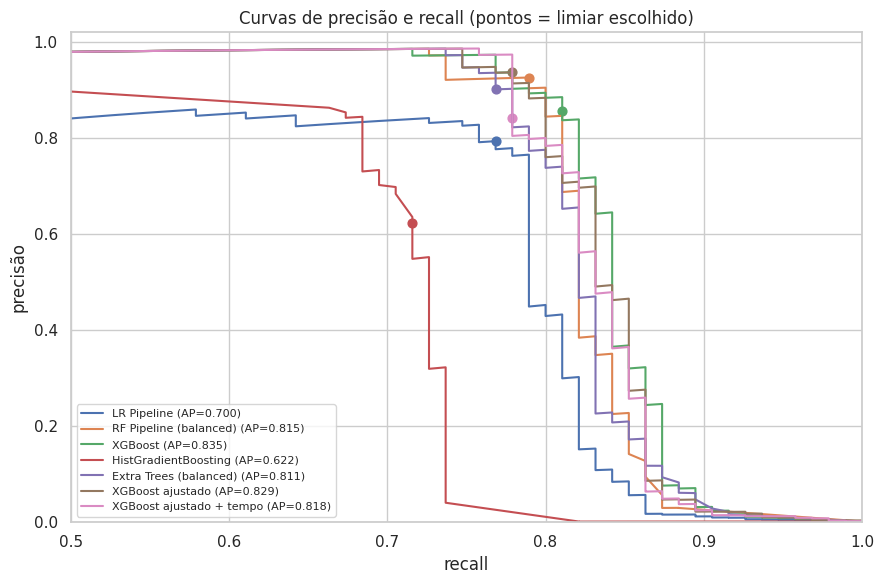

In [22]:
fig, ax = plt.subplots(figsize=(9, 6))
for nome, proba in probas_finais.items():
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ax.plot(rec, prec, label=f"{nome} (AP={average_precision_score(y_test, proba):.3f})")
    pred = proba >= limiares_oof[nome]
    ax.scatter(recall_score(y_test, pred), precision_score(y_test, pred), s=40)
ax.set(title="Curvas de precisão e recall (pontos = limiar escolhido)", xlabel="recall", ylabel="precisão",
       xlim=(0.5, 1.0), ylim=(0, 1.02))
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

## 7. Explicar

### 7.1 Importância das variáveis

A importância nativa das árvores diz quais variáveis o modelo mais usou, mas não diz em que direção elas empurram a decisão.

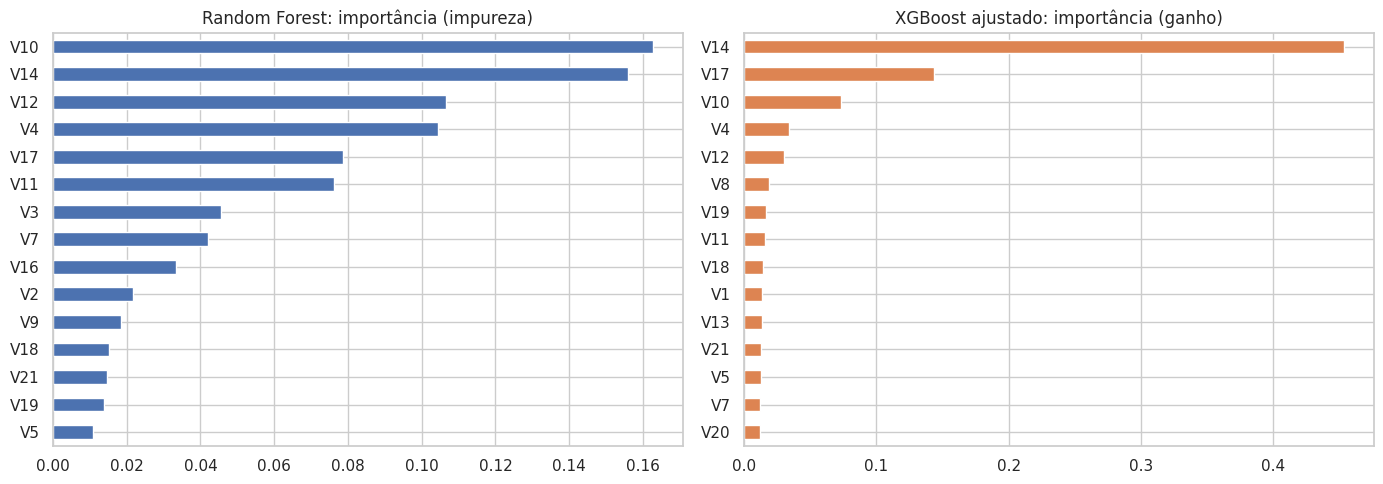

In [23]:
rf_pipe = candidatos["RF Pipeline (balanced)"]
imp_rf = pd.Series(rf_pipe.named_steps["modelo"].feature_importances_, index=FEATURES).sort_values(ascending=False)
imp_xgb = pd.Series(xgb_sem.feature_importances_, index=FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
imp_rf.head(15)[::-1].plot.barh(ax=axes[0], color="#4C72B0", title="Random Forest: importância (impureza)")
imp_xgb.head(15)[::-1].plot.barh(ax=axes[1], color="#DD8452", title="XGBoost ajustado: importância (ganho)")
plt.tight_layout()
plt.show()

### 7.2 SHAP

O SHAP decompõe a pontuação de cada transação na contribuição de cada variável. Uso o `TreeExplainer` no XGBoost ajustado (sem as variáveis de tempo), numa amostra do teste com **todas as fraudes** e 3.000 transações normais. Os valores estão em log-odds: positivo empurra para fraude, negativo para normal.

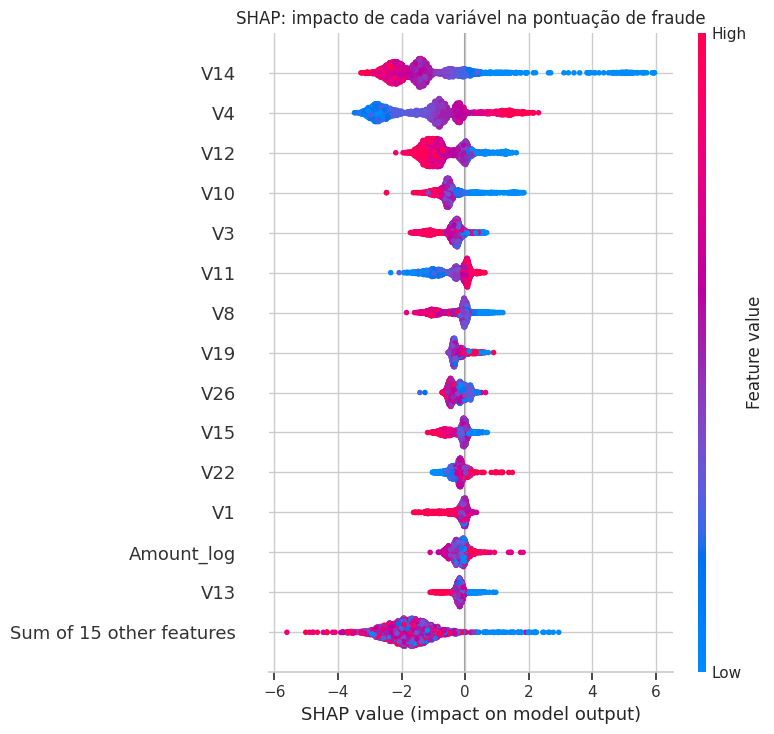

In [24]:
amostra_idx = np.concatenate([np.where(y_test == 1)[0],
                              rng.choice(np.where(y_test == 0)[0], size=3000, replace=False)])
X_amostra = X_test.iloc[amostra_idx]
explainer = shap.TreeExplainer(xgb_sem)
shap_values = explainer(X_amostra)

shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP: impacto de cada variável na pontuação de fraude")
plt.tight_layout()
plt.show()

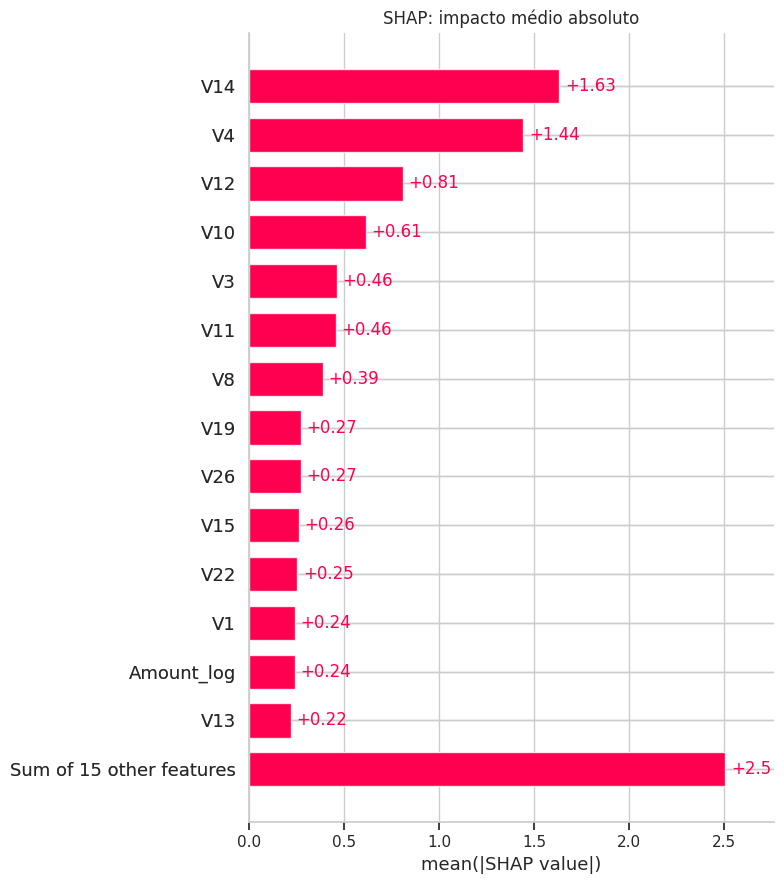

In [25]:
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("SHAP: impacto médio absoluto")
plt.tight_layout()
plt.show()

Fraude real com maior pontuação: probabilidade 1.0000


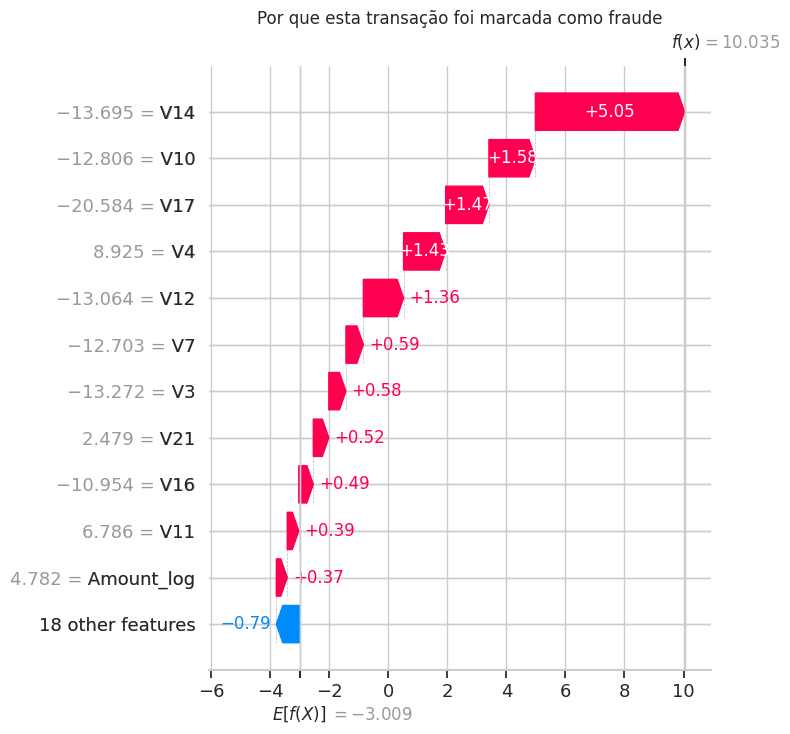

In [26]:
proba_amostra = xgb_sem.predict_proba(X_amostra)[:, 1]
y_amostra = y_test[amostra_idx]
pred_amostra = proba_amostra >= limiar_s

i_fraude = int(np.argmax(np.where(y_amostra == 1, proba_amostra, -1)))
print(f"Fraude real com maior pontuação: probabilidade {proba_amostra[i_fraude]:.4f}")
shap.plots.waterfall(shap_values[i_fraude], max_display=12, show=False)
plt.title("Por que esta transação foi marcada como fraude")
plt.tight_layout()
plt.show()

Na amostra: 0 falsos positivos e 21 fraudes perdidas no limiar 0.256
Fraude perdida com menor pontuação: probabilidade 0.0000


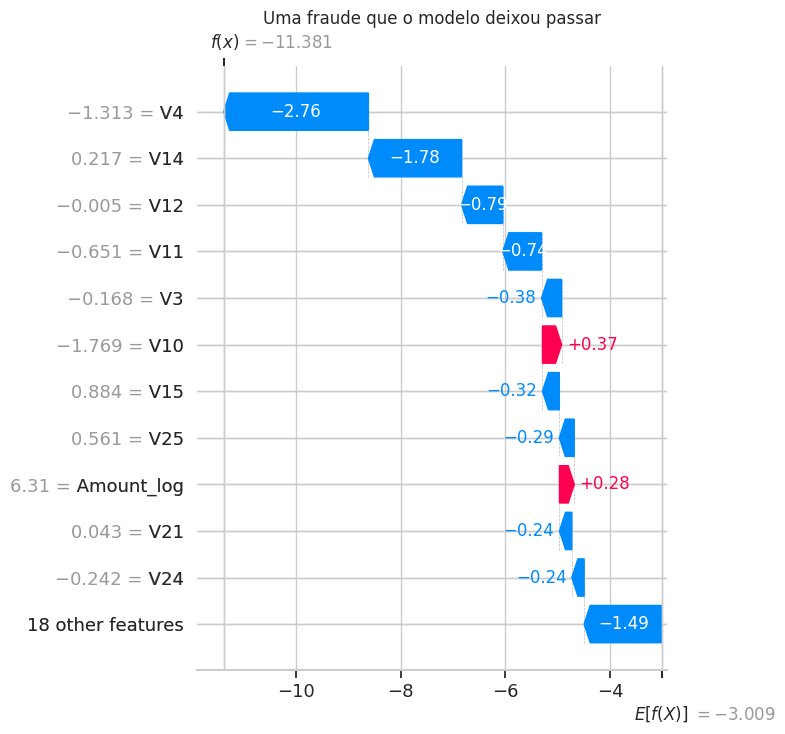

In [27]:
falsos_pos = np.where((y_amostra == 0) & pred_amostra)[0]
fraudes_perdidas = np.where((y_amostra == 1) & ~pred_amostra)[0]
print(f"Na amostra: {len(falsos_pos)} falsos positivos e {len(fraudes_perdidas)} fraudes perdidas no limiar {limiar_s:.3f}")

if len(fraudes_perdidas):
    j = int(fraudes_perdidas[np.argmin(proba_amostra[fraudes_perdidas])])
    print(f"Fraude perdida com menor pontuação: probabilidade {proba_amostra[j]:.4f}")
    shap.plots.waterfall(shap_values[j], max_display=12, show=False)
    plt.title("Uma fraude que o modelo deixou passar")
    plt.tight_layout()
    plt.show()

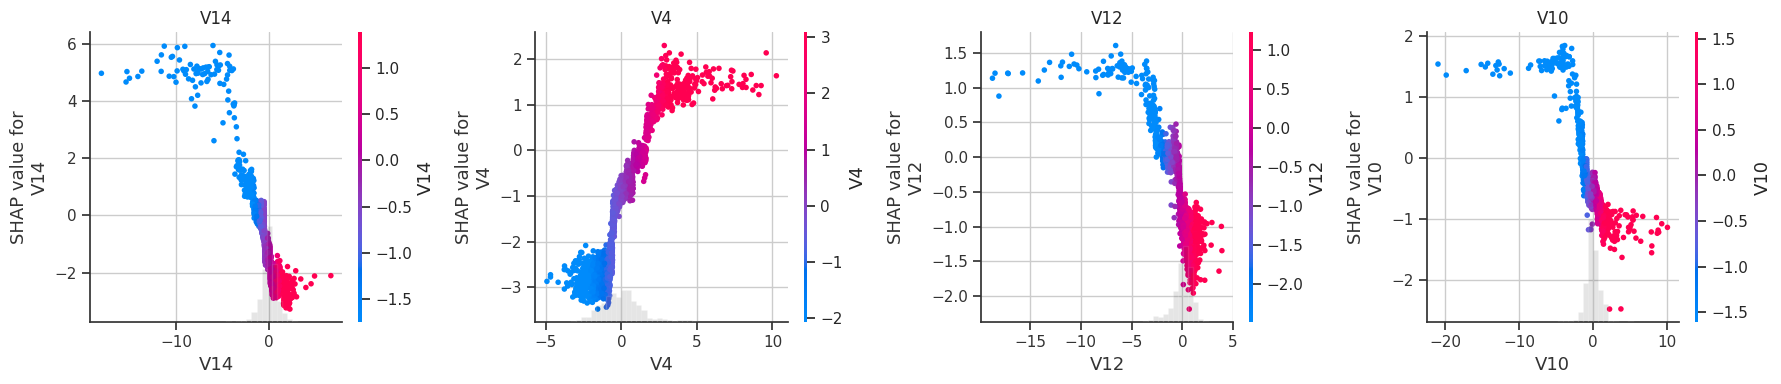

In [28]:
top4 = pd.Series(np.abs(shap_values.values).mean(0), index=FEATURES).sort_values(ascending=False).head(4).index
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, var in zip(axes, top4):
    shap.plots.scatter(shap_values[:, var], ax=ax, show=False, color=shap_values[:, var])
    ax.set_title(var)
plt.tight_layout()
plt.show()

## Conclusões

- **A acurácia não serve aqui**: o modelo que nunca acusa fraude tem 99,83% de acurácia e recall zero.
- **Melhor ranking**: XGBoost (PR-AUC 0,835 no teste; 0,853 na validação cruzada do modelo ajustado).
- **Modelo final**: XGBoost ajustado pelo GridSearchCV (`max_depth=5`, `learning_rate=0.05`, `scale_pos_weight=25`) com limiar **0,256**, escolhido pelo F2 nas previsões fora da dobra. No teste: recall 0,779 (74 de 95 fraudes), precisão 0,937, F1 0,851 e só 5 alarmes falsos em 56.746 transações.
- Se a prioridade for pegar o máximo de fraude, o XGBoost padrão no limiar 0,05 pega 77 de 95 (recall 0,811) com 13 alarmes falsos.
- **Amostragem**: undersampling e oversampling sobem o recall da regressão logística para 0,87, mas a precisão cai para cerca de 5%. Para o XGBoost, treinar sem amostragem e ajustar o limiar foi melhor.
- **Variáveis de tempo** não ajudaram: a PR-AUC caiu de 0,829 para 0,818. Sem identificador de cartão, elas descrevem o sistema, não o cliente.
- **SHAP**: V14, V4, V12 e V10 explicam a maior parte das decisões. Valores muito negativos de V14, V12 e V10 e valores altos de V4 empurram para fraude. O valor da transação pesa pouco.
- Com só 95 fraudes no teste, cada fraude vale cerca de 1 ponto de recall; diferenças de 2 ou 3 fraudes entre modelos estão dentro do ruído.